In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from scipy.stats import skew, kurtosis
from antropy import sample_entropy

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

# Complete EEG Analysis Pipeline

This notebook performs comprehensive EEG signal analysis including:
- Data loading and preprocessing
- Time-domain and frequency-domain feature extraction
- Statistical analysis
- Machine learning classification (Eyes Closed vs Eyes Open)
- Visualization of results

In [2]:
# Set up working directory and data path
# Raw recordings are not included in this repository (participant privacy).
# Files were renamed to anonymised IDs: <sub-XX>/<sub-XX>-<EC|EO>.txt
base_path = os.path.join("..", "data")
os.chdir(base_path)

# Get all subject folders
subject_folders = [f for f in os.listdir(base_path) if os.path.isdir(f) and f.startswith('sub-')]
print(f"Found {len(subject_folders)} subjects")
print("Subject folders:", sorted(subject_folders))

Found 15 subjects
Subject folders: ['sub-01', 'sub-02', 'sub-03', 'sub-04', 'sub-05', 'sub-06', 'sub-07', 'sub-08', 'sub-09', 'sub-10', 'sub-11', 'sub-12', 'sub-13', 'sub-14', 'sub-15']


In [3]:
# Function to load EEG data
def load_eeg_data(file_path):
    """Load EEG data from text file"""
    data = np.loadtxt(file_path)
    return data

# Function to parse filename info
def parse_filename(filename):
    """Extract subject ID and condition from an anonymised filename, e.g. sub-01-EC.txt"""
    stem = filename.replace('.EEG', '').replace('.txt', '')
    subject, condition = stem.rsplit('-', 1)
    return {
        'subject': subject,
        'condition': condition  # EC or EO
    }

# Test loading one file
test_file = os.path.join("sub-01", "sub-01-EC.txt")
test_data = load_eeg_data(test_file)
print(f"Data shape: {test_data.shape}")
print(f"Number of channels: {test_data.shape[1]}")
print(f"Number of samples: {test_data.shape[0]}")

Data shape: (52876, 19)
Number of channels: 19
Number of samples: 52876


In [4]:
# Load all EEG data files
all_data = []
metadata = []

for folder in sorted(subject_folders):
    folder_path = os.path.join(base_path, folder)
    files = [f for f in os.listdir(folder_path) if f.endswith('.txt')]
    
    for file in files:
        file_path = os.path.join(folder_path, file)
        try:
            data = load_eeg_data(file_path)
            info = parse_filename(file)
            info['folder'] = folder
            info['filename'] = file
            info['data'] = data
            
            all_data.append(data)
            metadata.append(info)
            print(f"Loaded: {file} - Shape: {data.shape}")
        except Exception as e:
            print(f"Error loading {file}: {e}")

print(f"\nTotal files loaded: {len(all_data)}")
df_metadata = pd.DataFrame(metadata)
print(df_metadata[['subject', 'condition']].head())

Loaded: sub-01-EC.txt - Shape: (52876, 19)
Loaded: sub-01-EO.txt - Shape: (60432, 19)
Loaded: sub-02-EC.txt - Shape: (60665, 19)
Loaded: sub-02-EO.txt - Shape: (60412, 19)
Loaded: sub-03-EC.txt - Shape: (61308, 19)
Loaded: sub-03-EO.txt - Shape: (61769, 19)
Loaded: sub-04-EC.txt - Shape: (53501, 19)
Loaded: sub-04-EO.txt - Shape: (53995, 19)
Loaded: sub-05-EC.txt - Shape: (53305, 19)
Loaded: sub-05-EO.txt - Shape: (60700, 19)
Loaded: sub-06-EC.txt - Shape: (75386, 19)
Loaded: sub-06-EO.txt - Shape: (75468, 19)
Loaded: sub-07-EC.txt - Shape: (61732, 19)
Loaded: sub-07-EO.txt - Shape: (60610, 19)
Loaded: sub-08-EC.txt - Shape: (62926, 19)
Loaded: sub-08-EO.txt - Shape: (67936, 19)
Loaded: sub-09-EC.txt - Shape: (60682, 19)
Loaded: sub-09-EO.txt - Shape: (60612, 19)
Loaded: sub-10-EC.txt - Shape: (68312, 19)
Loaded: sub-10-EO.txt - Shape: (60619, 19)
Loaded: sub-11-EC.txt - Shape: (62946, 19)
Loaded: sub-11-EO.txt - Shape: (63239, 19)
Loaded: sub-12-EC.txt - Shape: (68744, 19)
Loaded: sub

## Feature Extraction Functions

In [5]:
def extract_time_domain_features(signal):
    """Extract time-domain features from EEG signal"""
    features = {}
    
    # Statistical features
    features['mean'] = np.mean(signal)
    features['std'] = np.std(signal)
    features['var'] = np.var(signal)
    features['max'] = np.max(signal)
    features['min'] = np.min(signal)
    features['range'] = features['max'] - features['min']
    features['median'] = np.median(signal)
    features['skewness'] = skew(signal)
    features['kurtosis'] = kurtosis(signal)
    
    # Root Mean Square
    features['rms'] = np.sqrt(np.mean(signal**2))
    
    # Zero crossing rate
    zero_crossings = np.where(np.diff(np.sign(signal)))[0]
    features['zero_crossing_rate'] = len(zero_crossings) / len(signal)
    
    return features

In [6]:
def extract_frequency_domain_features(signal, fs=256):
    """Extract frequency-domain features from EEG signal"""
    features = {}
    
    # Compute FFT
    fft_vals = np.fft.fft(signal)
    fft_freq = np.fft.fftfreq(len(signal), 1/fs)
    
    # Get positive frequencies
    positive_freq_idx = fft_freq > 0
    fft_vals = np.abs(fft_vals[positive_freq_idx])
    fft_freq = fft_freq[positive_freq_idx]
    
    # Power Spectral Density
    psd = fft_vals ** 2
    
    # Define frequency bands
    delta = (0.5, 4)
    theta = (4, 8)
    alpha = (8, 13)
    beta = (13, 30)
    gamma = (30, 50)
    
    bands = {
        'delta': delta,
        'theta': theta,
        'alpha': alpha,
        'beta': beta,
        'gamma': gamma
    }
    
    # Calculate band powers
    for band_name, (low_freq, high_freq) in bands.items():
        band_idx = (fft_freq >= low_freq) & (fft_freq < high_freq)
        features[f'{band_name}_power'] = np.sum(psd[band_idx])
        features[f'{band_name}_relative_power'] = np.sum(psd[band_idx]) / np.sum(psd)
    
    # Spectral entropy
    psd_norm = psd / np.sum(psd)
    features['spectral_entropy'] = -np.sum(psd_norm * np.log2(psd_norm + 1e-10))
    
    # Peak frequency
    features['peak_frequency'] = fft_freq[np.argmax(psd)]
    
    return features

In [7]:
def extract_entropy_features(signal):
    """Extract entropy-based features - OPTIMIZED VERSION"""
    features = {}
    
    # Downsample signal for faster entropy calculation (use every 10th sample)
    downsampled = signal[::10]
    
    # Sample entropy (on downsampled data)
    try:
        features['sample_entropy'] = sample_entropy(downsampled)
    except:
        features['sample_entropy'] = 0
    
    # Skip approximate entropy as it's too slow - use spectral entropy instead
    # (spectral entropy is already calculated in frequency domain features)
    features['approximate_entropy'] = 0
    
    return features

In [8]:
def extract_all_features(data, fs=256):
    """Extract all features from multi-channel EEG data - ALL CHANNELS"""
    all_features = {}
    
    # Extract features from ALL channels
    for ch_idx in range(data.shape[1]):
        channel_signal = data[:, ch_idx]
        
        # Time-domain features (fast)
        time_features = extract_time_domain_features(channel_signal)
        for key, val in time_features.items():
            all_features[f'ch{ch_idx}_{key}'] = val
        
        # Frequency-domain features (fast)
        freq_features = extract_frequency_domain_features(channel_signal, fs)
        for key, val in freq_features.items():
            all_features[f'ch{ch_idx}_{key}'] = val
        
        # Entropy features (optimized with downsampling)
        entropy_features = extract_entropy_features(channel_signal)
        for key, val in entropy_features.items():
            all_features[f'ch{ch_idx}_{key}'] = val
    
    return all_features

# Test feature extraction on one sample
print("Extracting features from test sample...")
test_features = extract_all_features(test_data)
print(f"Total number of features: {len(test_features)}")
print(f"Sample features: {list(test_features.keys())[:10]}")

Extracting features from test sample...
Total number of features: 475
Sample features: ['ch0_mean', 'ch0_std', 'ch0_var', 'ch0_max', 'ch0_min', 'ch0_range', 'ch0_median', 'ch0_skewness', 'ch0_kurtosis', 'ch0_rms']


## Extract Features from All Subjects

In [9]:
# Extract features from all subjects
print("Extracting features from all subjects...")
all_features = []
labels = []

for idx, info in enumerate(metadata):
    try:
        features = extract_all_features(info['data'], fs=256)
        all_features.append(features)
        labels.append(1 if info['condition'] == 'EC' else 0)  # EC=1, EO=0
        
        if (idx + 1) % 5 == 0:
            print(f"Processed {idx + 1}/{len(metadata)} files...")
    except Exception as e:
        print(f"Error processing {info['filename']}: {e}")

# Create feature DataFrame
df_features = pd.DataFrame(all_features)
df_features['label'] = labels
df_features['condition'] = [m['condition'] for m in metadata]

print(f"\nFeature extraction complete!")
print(f"Feature matrix shape: {df_features.shape}")
print(f"Number of EC samples: {sum(labels)}")
print(f"Number of EO samples: {len(labels) - sum(labels)}")

Extracting features from all subjects...
Processed 5/30 files...
Processed 10/30 files...
Processed 15/30 files...
Processed 20/30 files...
Processed 25/30 files...
Processed 30/30 files...

Feature extraction complete!
Feature matrix shape: (30, 477)
Number of EC samples: 15
Number of EO samples: 15


## Data Visualization

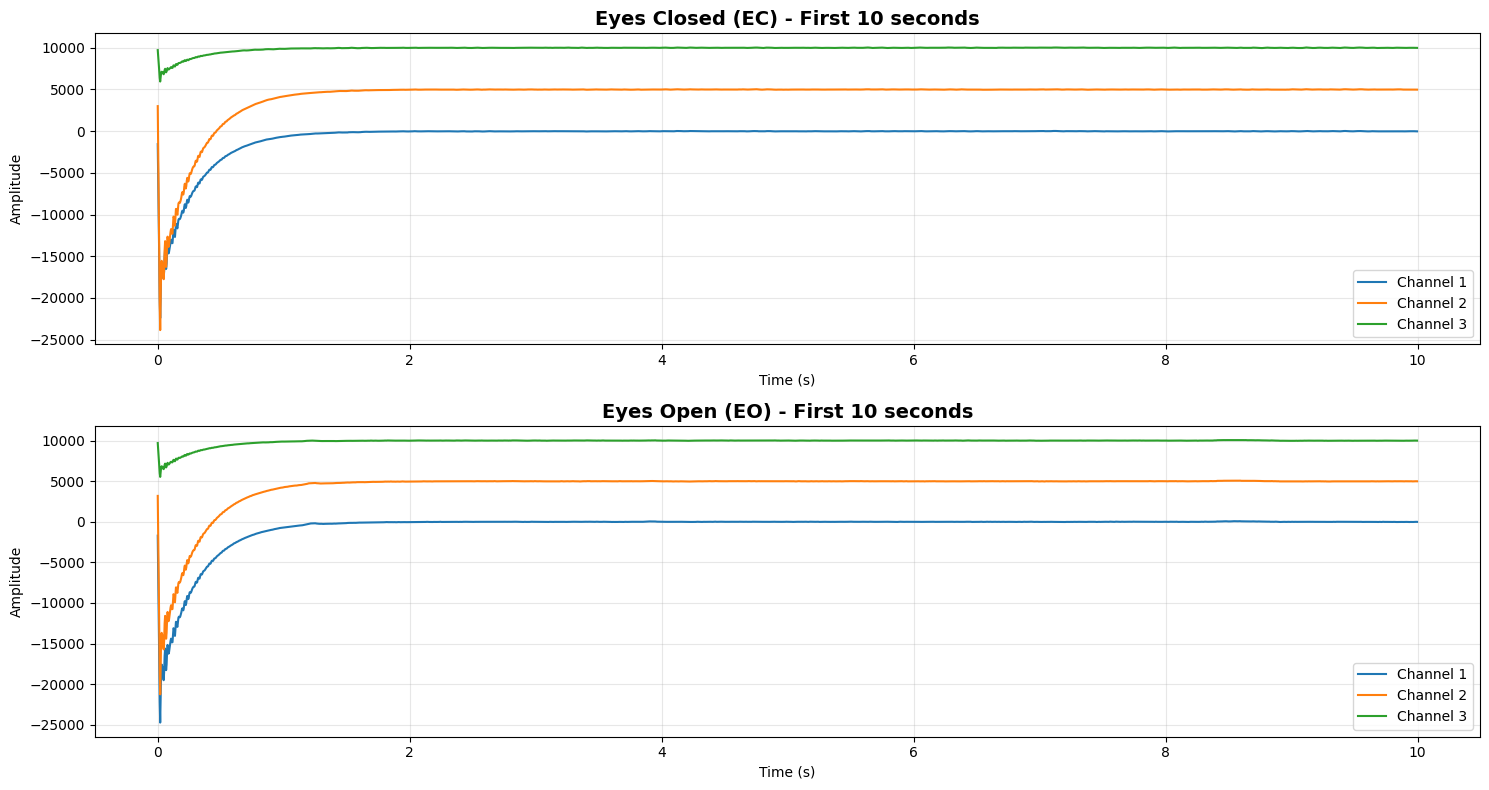

In [10]:
# Visualize sample EEG signals
fig, axes = plt.subplots(2, 1, figsize=(15, 8))

# Get one EC and one EO sample
ec_idx = df_features[df_features['condition'] == 'EC'].index[0]
eo_idx = df_features[df_features['condition'] == 'EO'].index[0]

ec_data = metadata[ec_idx]['data']
eo_data = metadata[eo_idx]['data']

# Plot first 3 channels of EC
time_ec = np.arange(ec_data.shape[0]) / 256
for ch in range(min(3, ec_data.shape[1])):
    axes[0].plot(time_ec[:2560], ec_data[:2560, ch] + ch*5000, label=f'Channel {ch+1}')
axes[0].set_title('Eyes Closed (EC) - First 10 seconds', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Time (s)')
axes[0].set_ylabel('Amplitude')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot first 3 channels of EO
time_eo = np.arange(eo_data.shape[0]) / 256
for ch in range(min(3, eo_data.shape[1])):
    axes[1].plot(time_eo[:2560], eo_data[:2560, ch] + ch*5000, label=f'Channel {ch+1}')
axes[1].set_title('Eyes Open (EO) - First 10 seconds', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Time (s)')
axes[1].set_ylabel('Amplitude')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

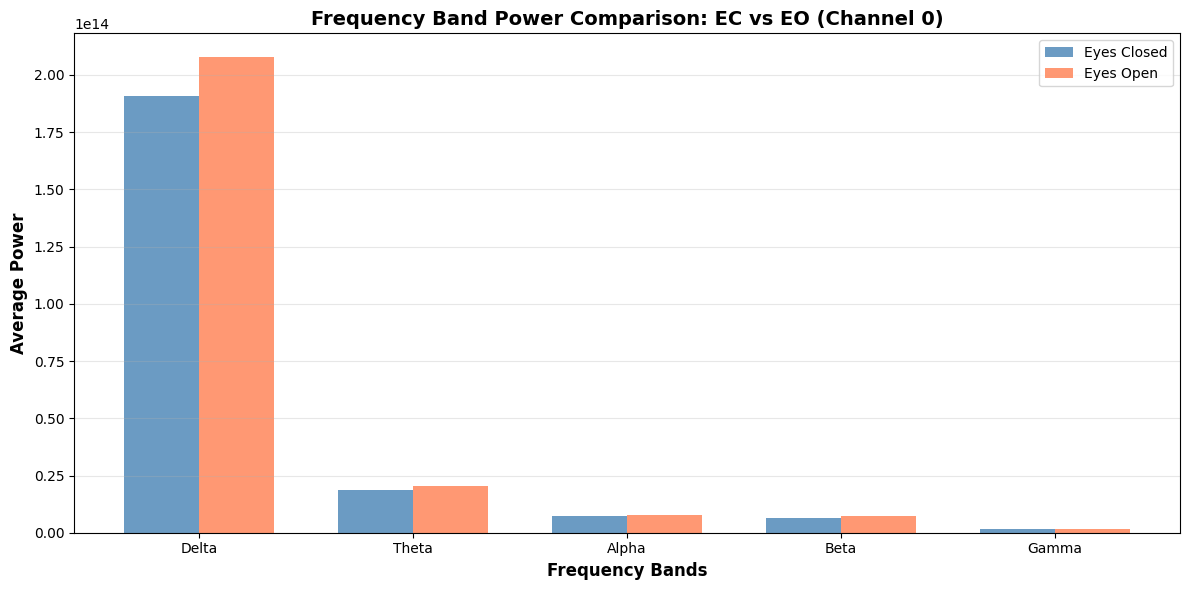

In [11]:
# Visualize frequency band power comparison
band_features = ['ch0_delta_power', 'ch0_theta_power', 'ch0_alpha_power', 'ch0_beta_power', 'ch0_gamma_power']
band_names = ['Delta', 'Theta', 'Alpha', 'Beta', 'Gamma']

ec_powers = df_features[df_features['condition'] == 'EC'][band_features].mean()
eo_powers = df_features[df_features['condition'] == 'EO'][band_features].mean()

x = np.arange(len(band_names))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 6))
bars1 = ax.bar(x - width/2, ec_powers, width, label='Eyes Closed', color='steelblue', alpha=0.8)
bars2 = ax.bar(x + width/2, eo_powers, width, label='Eyes Open', color='coral', alpha=0.8)

ax.set_xlabel('Frequency Bands', fontsize=12, fontweight='bold')
ax.set_ylabel('Average Power', fontsize=12, fontweight='bold')
ax.set_title('Frequency Band Power Comparison: EC vs EO (Channel 0)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(band_names)
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

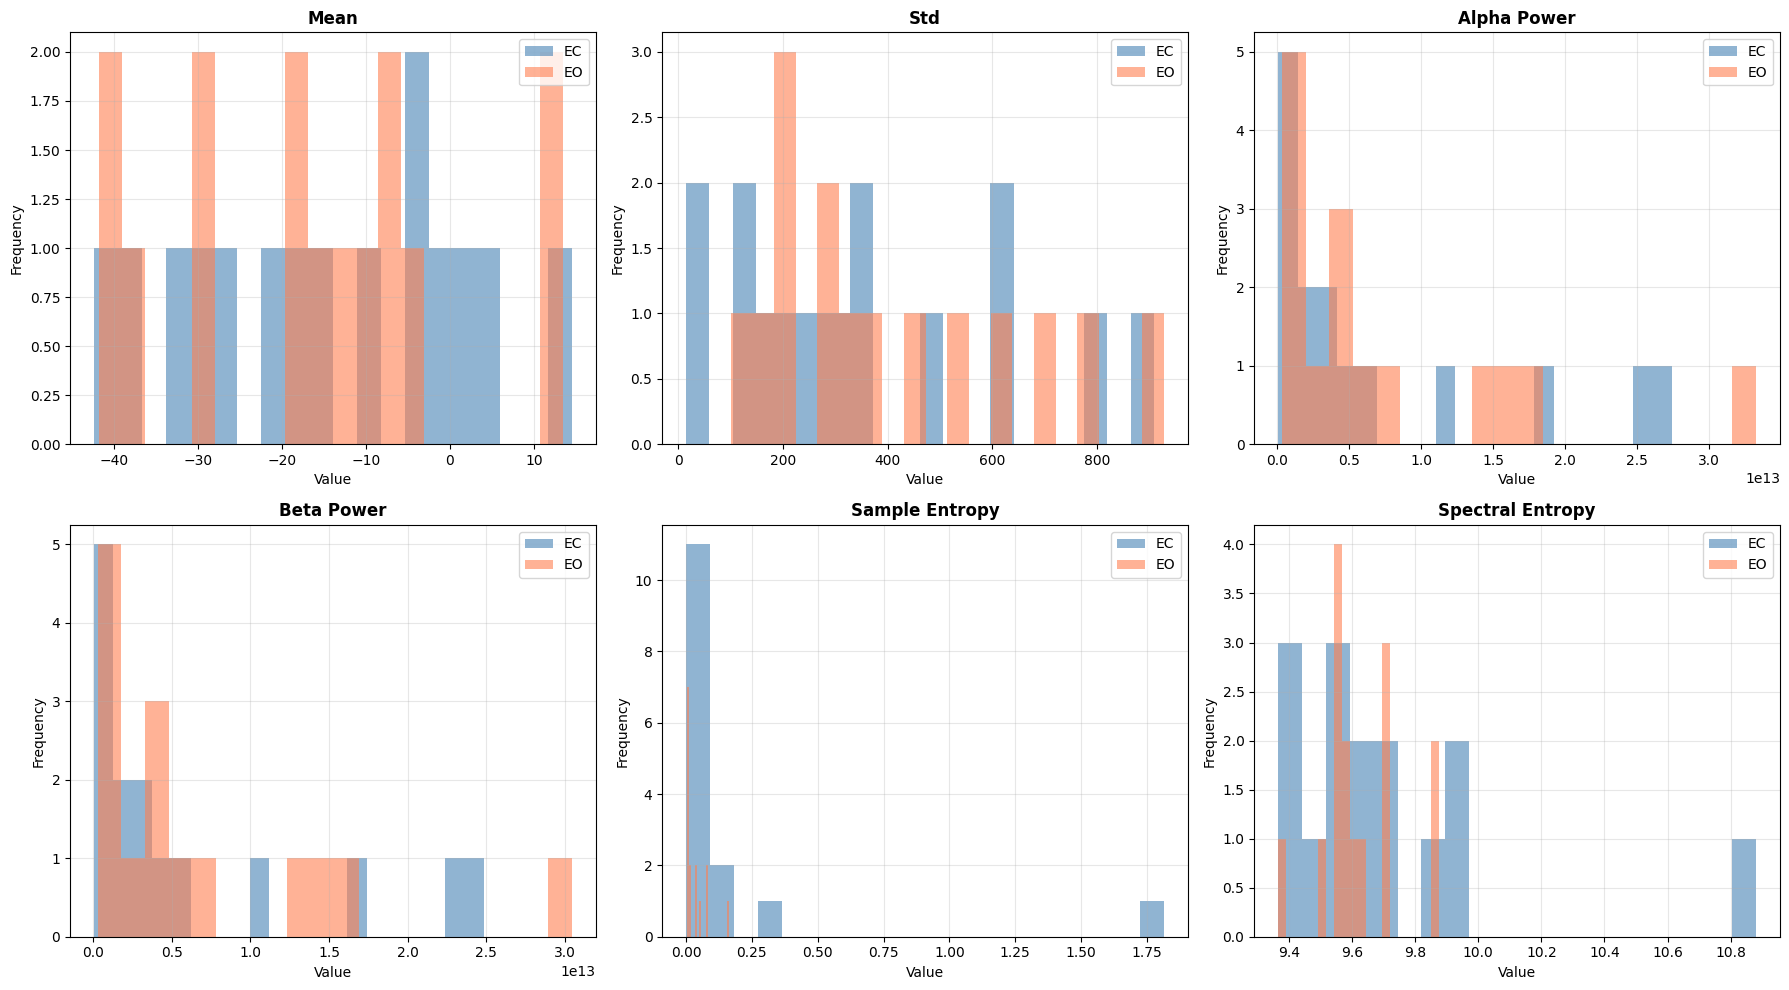

In [12]:
# Distribution of key features
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

feature_list = ['ch0_mean', 'ch0_std', 'ch0_alpha_power', 'ch0_beta_power', 'ch0_sample_entropy', 'ch0_spectral_entropy']

for idx, feature in enumerate(feature_list):
    if feature in df_features.columns:
        df_features[df_features['condition'] == 'EC'][feature].hist(ax=axes[idx], alpha=0.6, label='EC', bins=20, color='steelblue')
        df_features[df_features['condition'] == 'EO'][feature].hist(ax=axes[idx], alpha=0.6, label='EO', bins=20, color='coral')
        axes[idx].set_title(feature.replace('ch0_', '').replace('_', ' ').title(), fontweight='bold')
        axes[idx].set_xlabel('Value')
        axes[idx].set_ylabel('Frequency')
        axes[idx].legend()
        axes[idx].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Feature Selection and Dimensionality Reduction

In [13]:
# Prepare data for ML
X = df_features.drop(['label', 'condition'], axis=1)
y = df_features['label'].values

# Handle any NaN or Inf values
X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.mean())

print(f"Feature matrix shape: {X.shape}")
print(f"Labels shape: {y.shape}")
print(f"Class distribution - EC: {sum(y)}, EO: {len(y) - sum(y)}")

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print(f"\nPCA explained variance ratio: {pca.explained_variance_ratio_}")
print(f"Total variance explained: {sum(pca.explained_variance_ratio_):.2%}")

Feature matrix shape: (30, 475)
Labels shape: (30,)
Class distribution - EC: 15, EO: 15

PCA explained variance ratio: [0.19541111 0.11848164]
Total variance explained: 31.39%


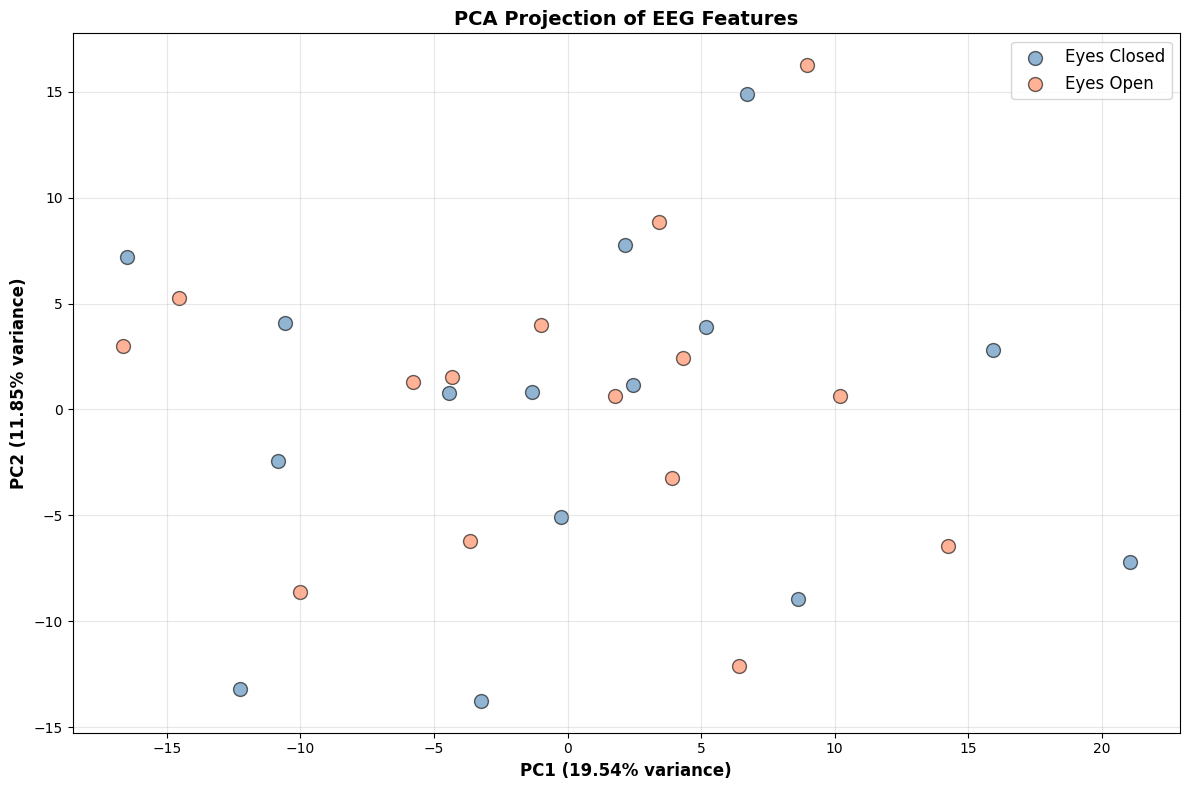

In [14]:
# Visualize PCA
plt.figure(figsize=(12, 8))

ec_mask = y == 1
eo_mask = y == 0

plt.scatter(X_pca[ec_mask, 0], X_pca[ec_mask, 1], c='steelblue', label='Eyes Closed', alpha=0.6, s=100, edgecolors='black')
plt.scatter(X_pca[eo_mask, 0], X_pca[eo_mask, 1], c='coral', label='Eyes Open', alpha=0.6, s=100, edgecolors='black')

plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%} variance)', fontsize=12, fontweight='bold')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%} variance)', fontsize=12, fontweight='bold')
plt.title('PCA Projection of EEG Features', fontsize=14, fontweight='bold')
plt.legend(fontsize=12)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Machine Learning Classification

In [15]:
# Initialize classifiers
classifiers = {
    'SVM': SVC(kernel='rbf', random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42)
}

# Cross-validation setup
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Store results
results = {
    'Classifier': [],
    'Accuracy': [],
    'Precision': [],
    'Recall': [],
    'F1-Score': []
}

print("Training and evaluating classifiers with 5-fold cross-validation...\n")

for clf_name, clf in classifiers.items():
    print(f"Training {clf_name}...")
    
    accuracies = []
    precisions = []
    recalls = []
    f1_scores = []
    
    for fold, (train_idx, test_idx) in enumerate(cv.split(X_scaled, y)):
        X_train, X_test = X_scaled[train_idx], X_scaled[test_idx]
        y_train, y_test = y[train_idx], y[test_idx]
        
        # Train
        clf.fit(X_train, y_train)
        
        # Predict
        y_pred = clf.predict(X_test)
        
        # Evaluate
        accuracies.append(accuracy_score(y_test, y_pred))
        precisions.append(precision_score(y_test, y_pred))
        recalls.append(recall_score(y_test, y_pred))
        f1_scores.append(f1_score(y_test, y_pred))
    
    # Store average results
    results['Classifier'].append(clf_name)
    results['Accuracy'].append(np.mean(accuracies))
    results['Precision'].append(np.mean(precisions))
    results['Recall'].append(np.mean(recalls))
    results['F1-Score'].append(np.mean(f1_scores))
    
    print(f"  Average Accuracy: {np.mean(accuracies):.4f} (+/- {np.std(accuracies):.4f})")
    print(f"  Average F1-Score: {np.mean(f1_scores):.4f} (+/- {np.std(f1_scores):.4f})\n")

# Create results DataFrame
df_results = pd.DataFrame(results)
print("\n" + "="*60)
print("FINAL RESULTS")
print("="*60)
print(df_results.to_string(index=False))

Training and evaluating classifiers with 5-fold cross-validation...

Training SVM...
  Average Accuracy: 0.3000 (+/- 0.1633)
  Average F1-Score: 0.2171 (+/- 0.1821)

Training KNN...
  Average Accuracy: 0.3000 (+/- 0.0667)
  Average F1-Score: 0.3571 (+/- 0.1969)

Training Random Forest...
  Average Accuracy: 0.5667 (+/- 0.1700)
  Average F1-Score: 0.5333 (+/- 0.2863)


FINAL RESULTS
   Classifier  Accuracy  Precision   Recall  F1-Score
          SVM  0.300000   0.250000 0.200000  0.217143
          KNN  0.300000   0.290000 0.466667  0.357143
Random Forest  0.566667   0.483333 0.600000  0.533333


### Interpreting the cross-validated results

With only 30 recordings (15 participants × 2 conditions), each test fold holds 6 samples, so a single misclassification moves accuracy by about 17 percentage points. SVM and KNN scored below chance and Random Forest was close to chance; none of these results is evidence that eye state can be classified reliably from this feature set. The main reasons are the very high ratio of features to samples (475 vs 30) and folds that are not grouped by participant. A more appropriate design would use leave-one-subject-out cross-validation, a small set of a-priori features (e.g. posterior alpha power) and a permutation test against chance.


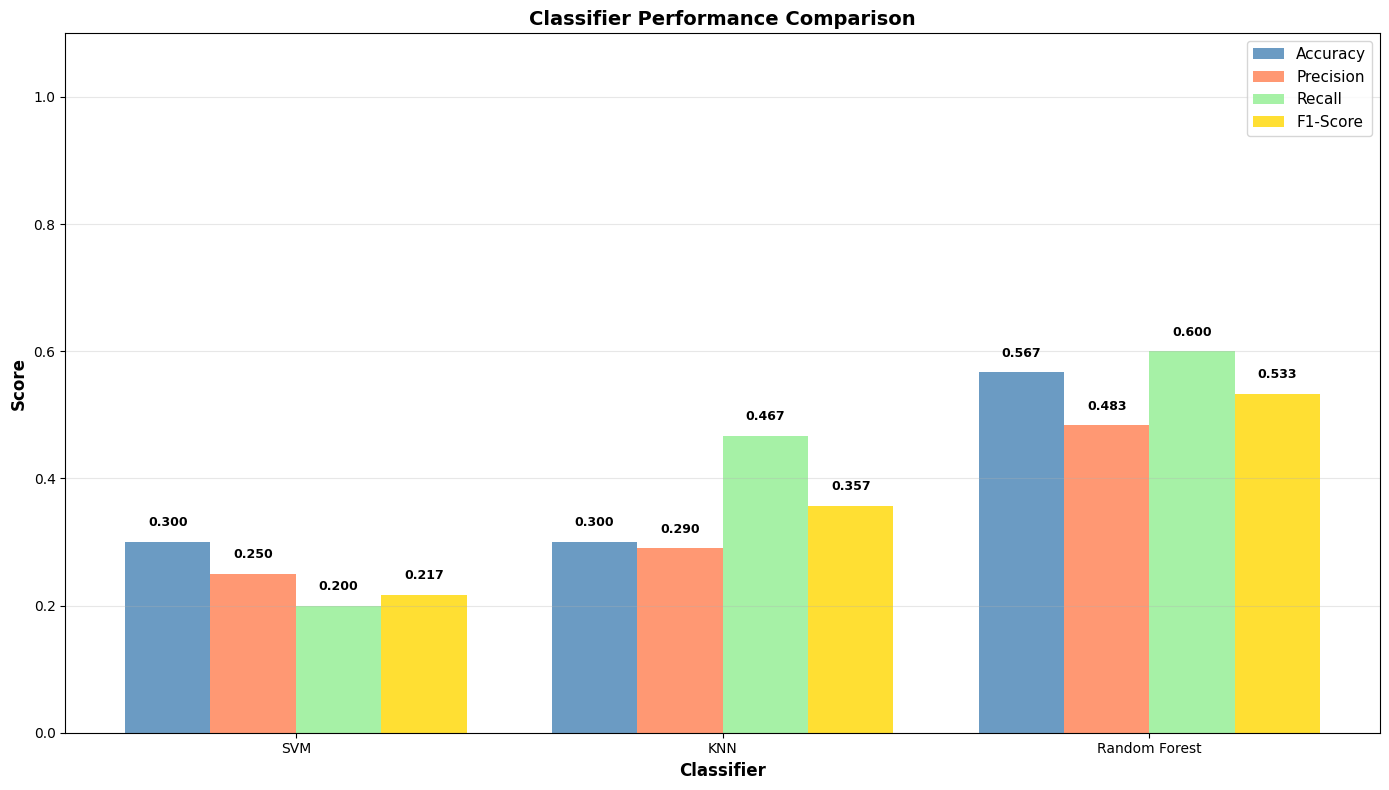

In [16]:
# Visualize classifier performance
fig, ax = plt.subplots(figsize=(14, 8))

x = np.arange(len(df_results))
width = 0.2

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
colors = ['steelblue', 'coral', 'lightgreen', 'gold']

for idx, metric in enumerate(metrics):
    offset = width * (idx - 1.5)
    ax.bar(x + offset, df_results[metric], width, label=metric, color=colors[idx], alpha=0.8)

ax.set_xlabel('Classifier', fontsize=12, fontweight='bold')
ax.set_ylabel('Score', fontsize=12, fontweight='bold')
ax.set_title('Classifier Performance Comparison', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(df_results['Classifier'])
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3, axis='y')
ax.set_ylim([0, 1.1])

# Add value labels on bars
for idx, metric in enumerate(metrics):
    offset = width * (idx - 1.5)
    for i, v in enumerate(df_results[metric]):
        ax.text(i + offset, v + 0.02, f'{v:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

### Note on the in-sample confusion matrix

The confusion matrix below is computed on the same data the model was trained on, so the perfect score only shows that the Random Forest can memorise 30 recordings. The cross-validated results above are the relevant estimate of performance.


Best Classifier: Random Forest
Training on full dataset (IN-SAMPLE fit, not a measure of generalisation)...



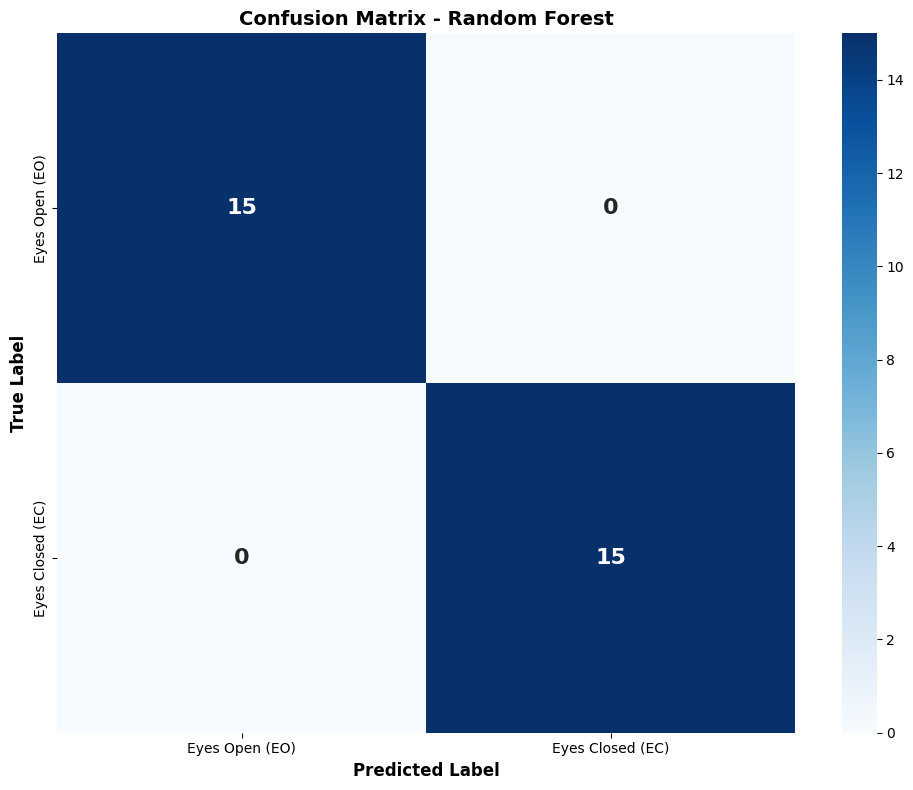


Classification Report:
                  precision    recall  f1-score   support

  Eyes Open (EO)       1.00      1.00      1.00        15
Eyes Closed (EC)       1.00      1.00      1.00        15

        accuracy                           1.00        30
       macro avg       1.00      1.00      1.00        30
    weighted avg       1.00      1.00      1.00        30



In [17]:
# Train best classifier on full data and show confusion matrix
best_clf_name = df_results.loc[df_results['Accuracy'].idxmax(), 'Classifier']
best_clf = classifiers[best_clf_name]

print(f"Best Classifier: {best_clf_name}")
print("Training on full dataset (IN-SAMPLE fit, not a measure of generalisation)...\n")

# Train on full dataset
best_clf.fit(X_scaled, y)
y_pred_full = best_clf.predict(X_scaled)

# Confusion matrix
cm = confusion_matrix(y, y_pred_full)

# Plot confusion matrix
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True, 
            xticklabels=['Eyes Open (EO)', 'Eyes Closed (EC)'],
            yticklabels=['Eyes Open (EO)', 'Eyes Closed (EC)'],
            annot_kws={"size": 16, "weight": "bold"})

ax.set_xlabel('Predicted Label', fontsize=12, fontweight='bold')
ax.set_ylabel('True Label', fontsize=12, fontweight='bold')
ax.set_title(f'Confusion Matrix - {best_clf_name}', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# Classification report
print("\nClassification Report:")
print("="*60)
print(classification_report(y, y_pred_full, target_names=['Eyes Open (EO)', 'Eyes Closed (EC)']))

## Feature Importance Analysis (Random Forest)

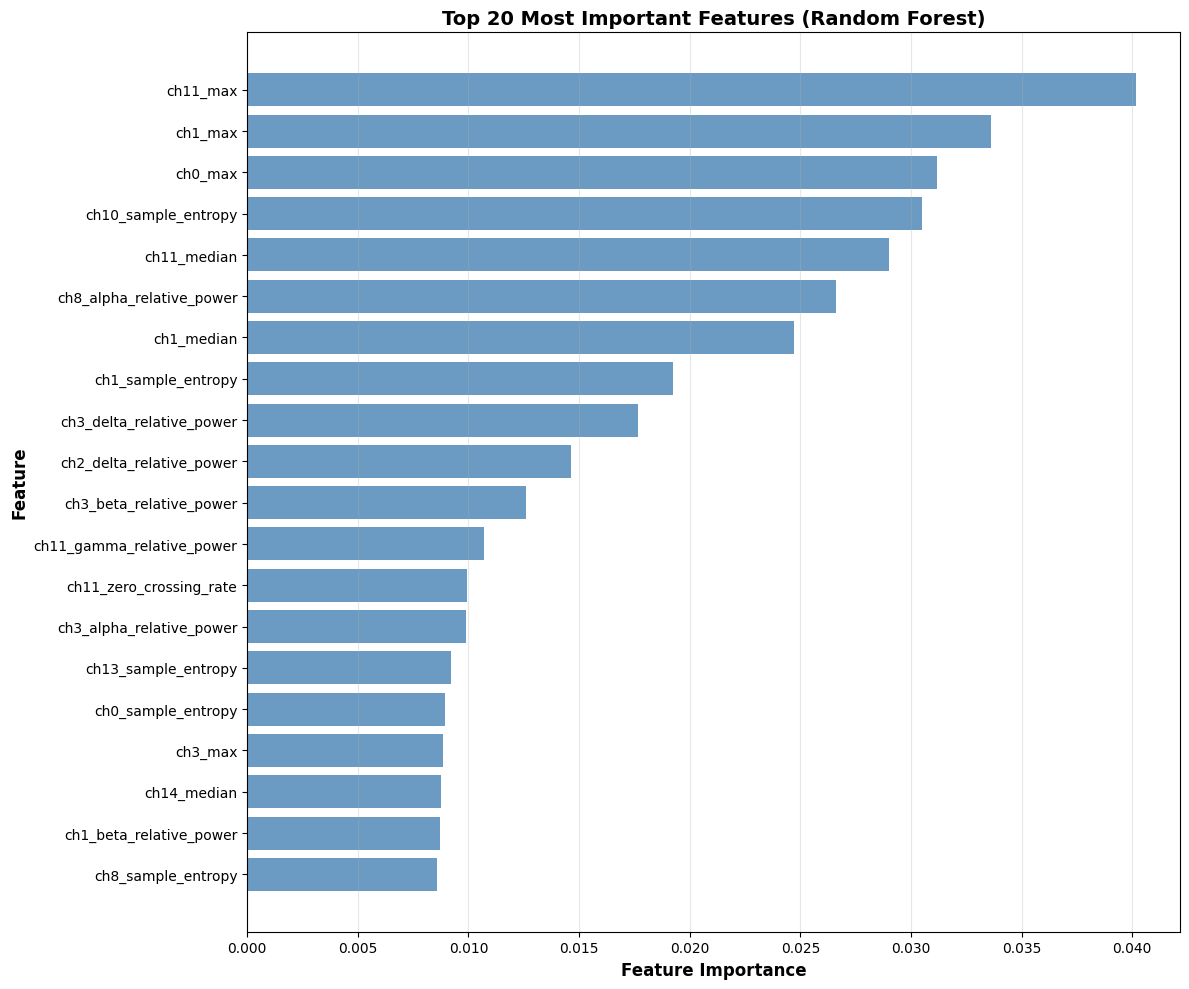


Top 10 Most Important Features:
                 feature  importance
                ch11_max    0.040152
                 ch1_max    0.033615
                 ch0_max    0.031185
     ch10_sample_entropy    0.030505
             ch11_median    0.029010
ch8_alpha_relative_power    0.026628
              ch1_median    0.024733
      ch1_sample_entropy    0.019232
ch3_delta_relative_power    0.017685
ch2_delta_relative_power    0.014629


In [18]:
# Get feature importance from Random Forest
rf_clf = classifiers['Random Forest']
rf_clf.fit(X_scaled, y)

feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': rf_clf.feature_importances_
}).sort_values('importance', ascending=False)

# Plot top 20 most important features
plt.figure(figsize=(12, 10))
top_features = feature_importance.head(20)
plt.barh(range(len(top_features)), top_features['importance'], color='steelblue', alpha=0.8)
plt.yticks(range(len(top_features)), top_features['feature'])
plt.xlabel('Feature Importance', fontsize=12, fontweight='bold')
plt.ylabel('Feature', fontsize=12, fontweight='bold')
plt.title('Top 20 Most Important Features (Random Forest)', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.show()

print("\nTop 10 Most Important Features:")
print("="*60)
print(feature_importance.head(10).to_string(index=False))

## Statistical Analysis

In [19]:
from scipy.stats import ttest_ind

# Perform t-tests for top features
print("Statistical Comparison: EC vs EO")
print("="*80)

ec_data = df_features[df_features['condition'] == 'EC']
eo_data = df_features[df_features['condition'] == 'EO']

top_feature_names = feature_importance.head(10)['feature'].values

stat_results = []
for feature in top_feature_names:
    ec_values = ec_data[feature].values
    eo_values = eo_data[feature].values
    
    t_stat, p_value = ttest_ind(ec_values, eo_values)
    
    stat_results.append({
        'Feature': feature,
        'EC Mean': np.mean(ec_values),
        'EO Mean': np.mean(eo_values),
        'T-Statistic': t_stat,
        'P-Value': p_value,
        'Significant': 'Yes' if p_value < 0.05 else 'No'
    })

df_stats = pd.DataFrame(stat_results)
print(df_stats.to_string(index=False))

# Count significant features
sig_count = (df_stats['P-Value'] < 0.05).sum()
print(f"\n{sig_count} out of {len(top_feature_names)} features are statistically significant (p < 0.05)")

Statistical Comparison: EC vs EO
                 Feature     EC Mean     EO Mean  T-Statistic  P-Value Significant
                ch11_max  304.677333  485.491333    -0.470356 0.641744          No
                 ch1_max 2289.926000 1585.998000     0.454949 0.652654          No
                 ch0_max 1835.576000 2520.561333    -0.349346 0.729443          No
     ch10_sample_entropy    0.000861    0.006690    -3.374563 0.002181         Yes
             ch11_median   -0.177333   -2.458667     3.207764 0.003339         Yes
ch8_alpha_relative_power    0.025240    0.036223    -0.654479 0.518144          No
              ch1_median   -0.759000   -3.491333     3.331672 0.002435         Yes
      ch1_sample_entropy    0.027644    0.061043    -0.915786 0.367600          No
ch3_delta_relative_power    0.436177    0.446713    -1.576683 0.126101          No
ch2_delta_relative_power    0.440508    0.446311    -2.253697 0.032232         Yes

4 out of 10 features are statistically significant (p

## Summary and Conclusions

In [20]:
print("="*80)
print("EEG ANALYSIS SUMMARY")
print("="*80)

print(f"\n1. DATASET INFORMATION:")
print(f"   - Total subjects: {len(subject_folders)}")
print(f"   - Total recordings: {len(metadata)}")
print(f"   - Eyes Closed (EC): {sum(y)} recordings")
print(f"   - Eyes Open (EO): {len(y) - sum(y)} recordings")
print(f"   - Number of channels: {test_data.shape[1]}")
print(f"   - Total features extracted: {X.shape[1]}")

print(f"\n2. BEST CLASSIFIER:")
print(f"   - Model: {best_clf_name}")
print(f"   - Accuracy: {df_results.loc[df_results['Accuracy'].idxmax(), 'Accuracy']:.4f}")
print(f"   - F1-Score: {df_results.loc[df_results['Accuracy'].idxmax(), 'F1-Score']:.4f}")

print(f"\n3. TOP 3 MOST IMPORTANT FEATURES:")
for idx, row in feature_importance.head(3).iterrows():
    print(f"   - {row['feature']}: {row['importance']:.4f}")

print(f"\n4. KEY FINDINGS:")
print(f"   - Cross-validated accuracy was below chance (SVM, KNN) or close to chance (Random Forest, 57%)")
print(f"   - With 30 recordings and 475 features, the models overfit (in-sample accuracy 100%)")
print(f"   - A few single features (e.g. sample entropy) differed between EC and EO in uncorrected t-tests")
print("\n" + "="*80)
print("Analysis Complete!")
print("="*80)

EEG ANALYSIS SUMMARY

1. DATASET INFORMATION:
   - Total subjects: 15
   - Total recordings: 30
   - Eyes Closed (EC): 15 recordings
   - Eyes Open (EO): 15 recordings
   - Number of channels: 19
   - Total features extracted: 475

2. BEST CLASSIFIER:
   - Model: Random Forest
   - Accuracy: 0.5667
   - F1-Score: 0.5333

3. TOP 3 MOST IMPORTANT FEATURES:
   - ch11_max: 0.0402
   - ch1_max: 0.0336
   - ch0_max: 0.0312

4. KEY FINDINGS:
   - Cross-validated accuracy was below chance (SVM, KNN) or close to chance (Random Forest, 57%)
   - With 30 recordings and 475 features, the models overfit (in-sample accuracy 100%)
   - A few single features (e.g. sample entropy) differed between EC and EO in uncorrected t-tests

Analysis Complete!
